# Imports

In [2]:
# stop - UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
import os
os.environ["OMP_NUM_THREADS"] = "1"

from utils import *

import pandas as pd
import numpy as np
from scipy.stats import norm, gaussian_kde
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

from matplotlib.lines import Line2D
from matplotlib.patches import Patch


# Setup

In [7]:
##############################
# Read Dataset into Dataframe
##############################

# path to cleaned dataset
clean_path = r'../data/mnz_cleaned.csv'

# structural zones for iteration
structural_zones = ['MDHSZ', 'GS', 'CBSZ', 'CMZI']

# type of grouping
group_type = 'kmeans'

# output path for interpretation
output_dir = r'../results'


timeline = [210, 450]
bar_width=0.4
gap=0.3


##### read into df...
df = pd.read_csv(clean_path)

# mask for garnet/cordierite lithologies (optional)...
# mask = (df['zone'] == 'MDHSZ') | (df['zone'] == 'GS') | (df['zone'] == 'CBSZ') | (df['zone'] == 'CMZI') & (df['garnet'] == 1)
mask = (df['zone'] == 'MDHSZ') | (df['zone'] == 'GS') | (df['zone'] == 'CBSZ') | (df['zone'] == 'CMZI') & (df['cordierite'] == 1)
df = df[mask]

df.sort_values('error', inplace=True)
df.reset_index(inplace=True)


df.head()

,level_0,index,sample,zone,mnz,texture,texture_chem,n,age,error,...,Er2O3,Tm2O3,Yb2O3,SO3,PbO,percent,lree,HREE,garnet,cordierite
0,2,176,P14-005A-5B,CBSZ,m20,core,Y depleted core,NaN,356.00,0.784962,...,0.014718,0.009812,0.009812,0.020605,0.079477,0.220495,61.972776,1.588568,1,0
1,1,111,P14-003-2B,MDHSZ,m50,core,Th enriched core,5.0,307.14,0.789124,...,0.009937,0.019969,0.009937,0.018184,0.132687,0.256926,57.520514,0.670830,1,0
2,3,114,M1605-2-L3,MDHSZ,m4,rim,Y depleted rim,5.0,298.70,1.346540,...,0.009748,0.009748,0.009748,0.016339,0.082968,0.450800,61.526147,1.376610,1,0
3,4,31,WA14-002,CMZI,m22,rim,Y depleted rim,5.0,353.24,1.408622,...,0.009641,0.060215,0.009641,0.014777,0.085454,0.398772,60.699177,1.389823,1,1
4,6,145,P14-005A-5B,CBSZ,m11,core,Y depleted core,NaN,360.00,1.446959,...,0.009646,0.009646,0.009646,0.012540,0.080065,0.401933,61.707991,1.223163,1,0


# K-Means

## Determine Number of Clusters

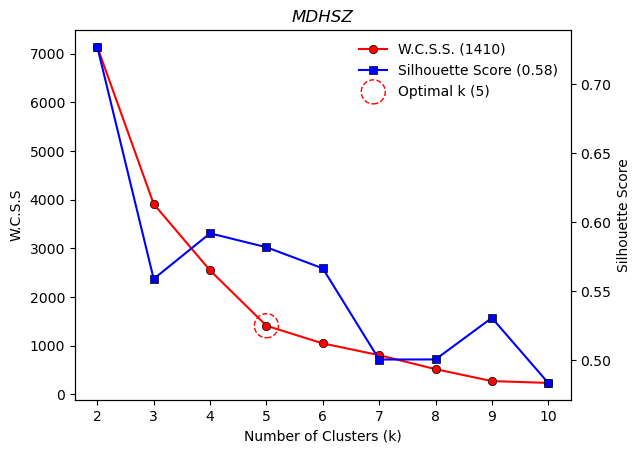

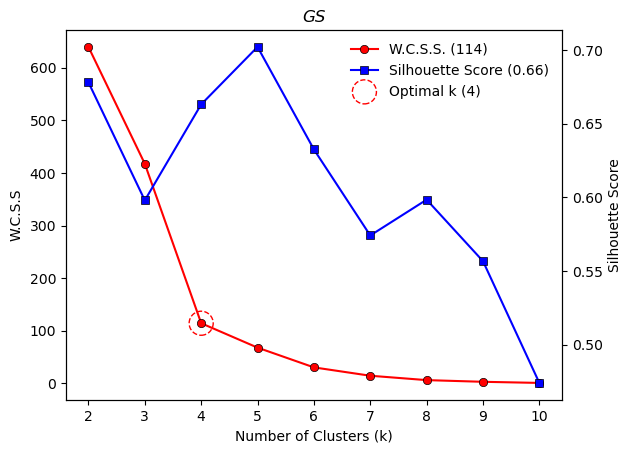

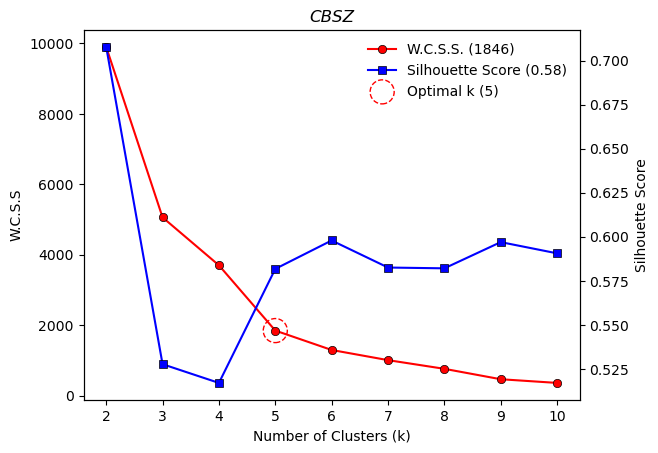

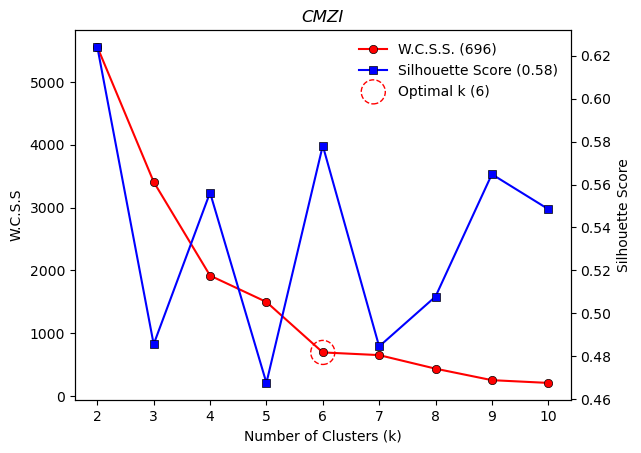

In [8]:

optimal_clusters = {}

for idx, zone in enumerate(structural_zones):

    df_subset = df[df['zone']==zone]
    ages = df_subset['age'].to_numpy().reshape(-1,1)

    clusters = np.arange(2, 11, 1)
    inertias = []
    sil_scores = []

    for k in clusters:
        kmeans = KMeans(n_clusters=k, random_state=111, n_init='auto').fit(ages)
        wcss = kmeans.inertia_
        sil = silhouette_score(ages, kmeans.labels_)
        inertias.append(wcss)
        sil_scores.append(sil)
    
    inertias = np.asarray(inertias, dtype=float)
    sil_scores = np.asarray(sil_scores, dtype=float)

    fig, ax = plt.subplots()
    ax2 = ax.twinx()

    optimal_k = relative_drop_kmeans_k(inertias, start_k=2, min_gain=0.05, alpha=0.9, lookahead=2)
    optimal_clusters[zone] = optimal_k

    k_plot = ax.scatter(clusters[optimal_k-2], inertias[optimal_k-2], edgecolors='red', facecolors='none', linestyle='--', s=300, label=f"Optimal k ({optimal_k})")
    (wcss_plot,) = ax.plot(clusters, inertias, color='red', marker='o', markeredgecolor='k', markeredgewidth=0.5, label=f"W.C.S.S. ({int(inertias[optimal_k-2])})")
    (sil_plot,) = ax2.plot(clusters, sil_scores, color='blue', marker='s', markeredgecolor='k', markeredgewidth=0.5, label=f"Silhouette Score ({round(sil_scores[optimal_k-2], 2)})")


    legend_items = [wcss_plot, sil_plot, k_plot]
    ax.legend(handles=legend_items, loc='upper right', bbox_to_anchor=(1,1), frameon=False)

    ax.set_title(zone, style='italic')
    ax.set_xlabel('Number of Clusters (k)')
    ax.set_ylabel('W.C.S.S')
    ax2.set_ylabel('Silhouette Score')


    output_path = f"{output_dir}/{group_type}_elbow_{zone}_CRD"
    plt.savefig(output_path + '.png', dpi=300, pad_inches=0, bbox_inches='tight')
    plt.savefig(output_path + '.svg', dpi=300, pad_inches=0, bbox_inches='tight')

    plt.show()


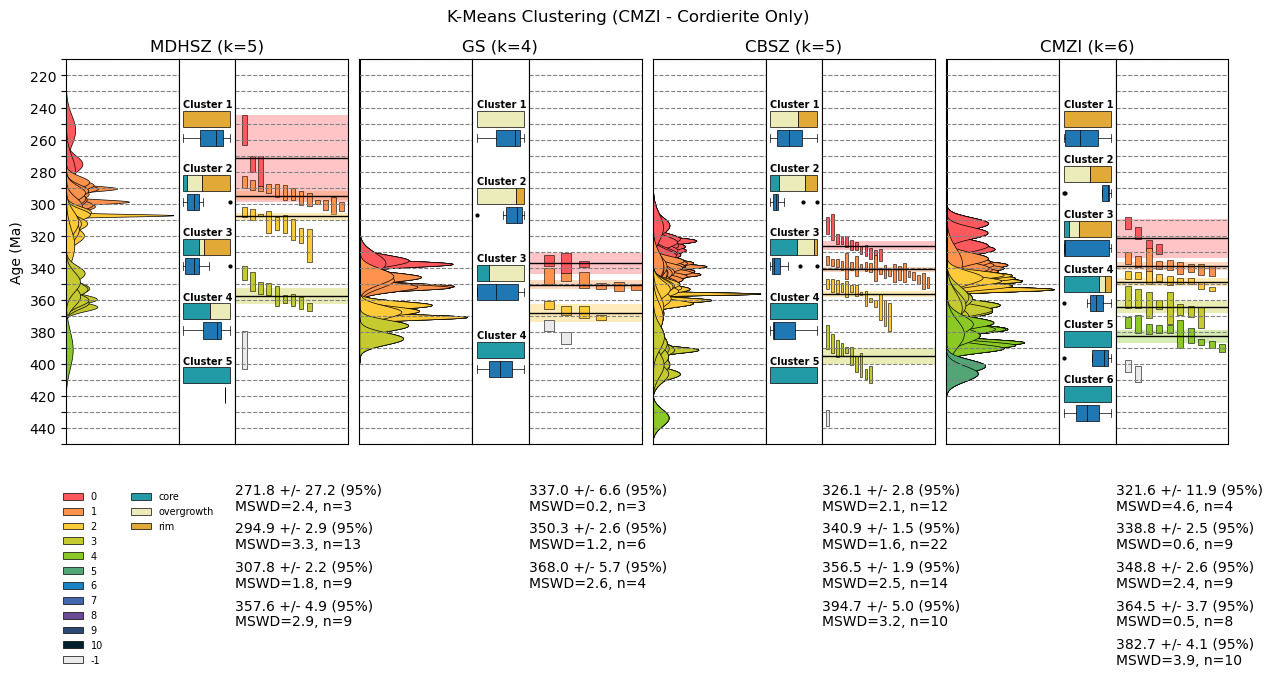

In [9]:



##### Plot figure...

fig = plt.figure(figsize=(15, 5))
width_ratios = [1.0, 0.5, 1.0, 0.1, 1.0, 0.5, 1.0, 0.1, 1.0, 0.5, 1.0, 0.1, 1.0, 0.5, 1.0]
gs = GridSpec(nrows=1, ncols=15, figure=fig, wspace=0, width_ratios=width_ratios)

# define axes - left triplet (A), spacer (hidden), right triplet (B)...
axA_1 = fig.add_subplot(gs[0, 0])
axA_2 = fig.add_subplot(gs[0, 1], sharey=axA_1)
axA_3 = fig.add_subplot(gs[0, 2], sharey=axA_1)
ax_sp1 = fig.add_subplot(gs[0, 3])                 # spacer
axB_1 = fig.add_subplot(gs[0, 4], sharey=axA_1)
axB_2 = fig.add_subplot(gs[0, 5], sharey=axA_1)
axB_3 = fig.add_subplot(gs[0, 6], sharey=axA_1)
ax_sp2 = fig.add_subplot(gs[0, 7])                 # spacer
axC_1 = fig.add_subplot(gs[0, 8], sharey=axA_1)
axC_2 = fig.add_subplot(gs[0, 9], sharey=axA_1)
axC_3 = fig.add_subplot(gs[0, 10], sharey=axA_1)
ax_sp3 = fig.add_subplot(gs[0, 11])                 # spacer
axD_1 = fig.add_subplot(gs[0, 12], sharey=axA_1)
axD_2 = fig.add_subplot(gs[0, 13], sharey=axA_1)
axD_3 = fig.add_subplot(gs[0, 14], sharey=axA_1)

# hide spacer axes...
ax_sp1.axis("off")
ax_sp2.axis("off")
ax_sp3.axis("off")


axA_1.set_ylim(450, 210)


panel1_max = [0.0, 0.0, 0.0, 0.0]
panel2_max = [0.0, 0.0, 0.0, 0.0]
panel3_max = [0.0, 0.0, 0.0, 0.0]


# iterate through structural zones...
for idx, zone in enumerate(structural_zones):

    df_subset = df.loc[df['zone']==zone].copy()
    df_kmeans = kmeans_processing(df_subset, optimal_clusters[zone])
    num_clusters = len(df_kmeans['labels'].unique())
    cluster_labels = df_kmeans['labels'].unique()
    y_max = df_kmeans['Y2O3'].max()


    # iterate through each cluster label...
    for k, cluster in enumerate(cluster_labels):

        df_kmeans_subset = df_kmeans.loc[df_kmeans['labels'] == cluster].copy()
        spacing = (450-210) / (num_clusters + 1)
        center = 240 + (k * spacing)
        
    
        # logic control to contain structural zone information...
        # MDHSZ...
        if idx==0:

            sample_max = plot_samples_panel(df_kmeans_subset, axA_1, 'labels', age_group_colors, label_bool=True)

            plot_ageinterp_panel(df_kmeans_subset, axA_3, cluster, age_group_colors, ci='95%')

            texture_counts = df_kmeans_subset['texture'].value_counts().to_dict()
            texture_counts = dict(sorted(texture_counts.items()))
            horizontal_stack(axA_2, k, center, texture_counts, texture_colors, df_kmeans_subset['Y2O3'].to_numpy())
            
            axA_2.set_title(f"{zone} (k={num_clusters})", loc='center')

            # plot age group information below plot...
            ages = df_kmeans_subset['age'].to_numpy()
            errors = df_kmeans_subset['error'].to_numpy()
            stats = cluster_stats(ages, errors, ci='95%')
            label = ''
            if stats['n'] >= 3:
                # label = f"\n{round(stats['mean'],1)} +/- {round(stats['halfwidth'],1)} (2 sig.)\nMSWD={round(stats['mswd'], 1)}\n"
                label += f"{round(stats['mean'], 1)} +/- {round(stats['halfwidth'], 1)} (95%)\nMSWD={round(stats['mswd'], 1)}, n={stats['n']}"
            axA_3.text(0, -0.1-(k/10), label, transform=axA_3.transAxes, fontsize=10, ha='left', va='top')

            
        elif idx==1:
            sample_max = plot_samples_panel(df_kmeans, axB_1, 'labels', age_group_colors, label_bool=False)

            plot_ageinterp_panel(df_kmeans_subset, axB_3, cluster, age_group_colors, ci='95%')

            texture_counts = df_kmeans_subset['texture'].value_counts().to_dict()
            texture_counts = dict(sorted(texture_counts.items()))
            horizontal_stack(axB_2, k, center, texture_counts, texture_colors, df_kmeans_subset['Y2O3'].to_numpy())

            axB_2.set_title(f"{zone} (k={num_clusters})", loc='center')

            # plot age group information below plot...
            ages = df_kmeans_subset['age'].to_numpy()
            errors = df_kmeans_subset['error'].to_numpy()
            stats = cluster_stats(ages, errors, ci='95%')
            label = ''
            if stats['n'] >= 3:
                # label = f"\n{round(stats['mean'],1)} +/- {round(stats['halfwidth'],1)} (2 sig.)\nMSWD={round(stats['mswd'], 1)}\n"
                label += f"{round(stats['mean'], 1)} +/- {round(stats['halfwidth'], 1)} (95%)\nMSWD={round(stats['mswd'], 1)}, n={stats['n']}"
            axB_3.text(0, -0.1-(k/10), label, transform=axB_3.transAxes, fontsize=10, ha='left', va='top')
        

        elif idx==2:
            sample_max = plot_samples_panel(df_kmeans, axC_1, 'labels', age_group_colors, label_bool=False)

            plot_ageinterp_panel(df_kmeans_subset, axC_3, cluster, age_group_colors, ci='95%')
            
            texture_counts = df_kmeans_subset['texture'].value_counts().to_dict()
            texture_counts = dict(sorted(texture_counts.items()))
            horizontal_stack(axC_2, k, center, texture_counts, texture_colors, df_kmeans_subset['Y2O3'].to_numpy())


            axC_2.set_title(f"{zone} (k={num_clusters})", loc='center')

            # plot age group information below plot...
            ages = df_kmeans_subset['age'].to_numpy()
            errors = df_kmeans_subset['error'].to_numpy()
            stats = cluster_stats(ages, errors, ci='95%')
            label = ''
            if stats['n'] >= 3:
                # label = f"\n{round(stats['mean'],1)} +/- {round(stats['halfwidth'],1)} (2 sig.)\nMSWD={round(stats['mswd'], 1)}\n"
                label += f"{round(stats['mean'], 1)} +/- {round(stats['halfwidth'], 1)} (95%)\nMSWD={round(stats['mswd'], 1)}, n={stats['n']}"
            axC_3.text(0, -0.1-(k/10), label, transform=axC_3.transAxes, fontsize=10, ha='left', va='top')
        
        
        elif idx==3:
            sample_max = plot_samples_panel(df_kmeans, axD_1, 'labels', age_group_colors, label_bool=False)

            plot_ageinterp_panel(df_kmeans_subset, axD_3, cluster, age_group_colors, ci='95%')
            
            texture_counts = df_kmeans_subset['texture'].value_counts().to_dict()
            texture_counts = dict(sorted(texture_counts.items()))
            horizontal_stack(axD_2, k, center, texture_counts, texture_colors, df_kmeans_subset['Y2O3'].to_numpy())
            
            axD_2.set_title(f"{zone} (k={num_clusters})", loc='center')

            # plot age group information below plot...
            ages = df_kmeans_subset['age'].to_numpy()
            errors = df_kmeans_subset['error'].to_numpy()
            stats = cluster_stats(ages, errors, ci='95%')
            label = ''
            if stats['n'] >= 3:
                # label = f"\n{round(stats['mean'],1)} +/- {round(stats['halfwidth'],1)} (2 sig.)\nMSWD={round(stats['mswd'], 1)}\n"
                label += f"{round(stats['mean'], 1)} +/- {round(stats['halfwidth'], 1)} (95%)\nMSWD={round(stats['mswd'], 1)}, n={stats['n']}"
            axD_3.text(0, -0.1-(k/10), label, transform=axD_3.transAxes, fontsize=10, ha='left', va='top')


        panel1_max[idx] = max(panel1_max[idx], sample_max)
        panel2_max[idx] = max(panel2_max[idx], y_max)
    panel3_max[idx] = df_kmeans.value_counts('labels').max()


# hard-pin the inverted y on all shared siblings
for a in axA_1.get_shared_y_axes().get_siblings(axA_1):
    a.set_ylim(450, 210)
    a.set_autoscale_on(False)

# also pin the memoized twins so they cannot drift
for mid in (axA_2, axB_2, axC_2, axD_2):
    if hasattr(mid, "_box_twin"):
        mid._box_twin.set_ylim(450, 210)
        mid._box_twin.set_autoscale_on(False)



axA_1.set_xlim(0, panel1_max[0] * 1.05)
# axA_2.set_xlim(-0.1, panel2_max[0] * 0.9)
axA_3.set_xlim(0, panel3_max[0] * (bar_width + gap + 0.05))

axB_1.set_xlim(0, panel1_max[1] * 1.05)
axB_3.set_xlim(0, panel3_max[1] * (bar_width + gap + 0.05))

axC_1.set_xlim(0, panel1_max[2]  * 1.05)
axC_3.set_xlim(0, panel3_max[2] * (bar_width + gap + 0.05))

axD_1.set_xlim(0, panel1_max[3]  * 1.05)
axD_3.set_xlim(0, panel3_max[3] * (bar_width + gap + 0.05))



# create legend...

patches = []
for k,v in age_group_colors.items():
    patches.append(Patch(facecolor=v, edgecolor='k', linewidth=0.5, label=k))

# create legend for texture
axA_1.legend(patches, [l.get_label() for l in patches], loc='upper left', bbox_to_anchor=(-0.1,-0.1), frameon=False, fontsize=7)


# patches for texture...
patches = []
for k,v in texture_colors.items():
    patches.append(Patch(facecolor=v, edgecolor='k', linewidth=0.5, label=k))
axA_2.legend(patches, [l.get_label() for l in patches], loc='upper left', bbox_to_anchor=(-1,-0.1), frameon=False, fontsize=7)


plt.suptitle('K-Means Clustering (CMZI - Cordierite Only)')

output_path = f"{output_dir}/{group_type}_interpretation_CRD"
plt.savefig(output_path + '.png', dpi=300, pad_inches=0, bbox_inches='tight')
plt.savefig(output_path + '.svg', dpi=300, pad_inches=0, bbox_inches='tight')

plt.show()